# PolloSoft – Knowledge Management Prototype

**Knowledge Management – TECMILENIO**

Team:
- Daniela Alejandra Escamilla Alanis (T03086448)
- Leonardo Alonso González del Ángel (T03098643)
- Dana Elena Zertuche Castro (T02991408)

In this notebook we build a small prototype of a knowledge management system for **PolloSoft**, our fictional iOS app studio. The prototype does two things:

1. **Automatic document classification:** it reads a document and predicts its category (TF-IDF + Naive Bayes / Logistic Regression).
2. **Semantic search:** it finds the most similar documents to a question written in natural language (TF-IDF + cosine similarity).

At the end we also draw a simple ontology (concept map) of PolloSoft's knowledge.

To run it: `Runtime → Run all`.

In [1]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.pipeline import make_pipeline

pd.set_option("display.max_colwidth", 100)

## 1. Dataset

We wrote 48 short mock documents that represent the knowledge PolloSoft handles every day. There are 8 documents for each of these 6 categories:

| Category | Examples |
|---|---|
| Technical Guide | architecture guides (SwiftUI, SwiftData, CloudKit, StoreKit 2) |
| Deployment SOP | step-by-step procedures for App Store Connect and TestFlight |
| Bug Report | bug reports and QA test results |
| Analytics Report | revenue (ARR), crashes, retention, downloads |
| Marketing Plan | social media, App Store Optimization (ASO), campaigns |
| Policy | privacy, security and onboarding policies |

In [2]:
documents = [
    # ---------- Technical Guide ----------
    {"title": "NestNotes architecture", "category": "Technical Guide",
     "text": "NestNotes saves every note locally with SwiftData first and then syncs it to iCloud using CloudKit, so the app works offline."},
    {"title": "SwiftUI MVVM guide", "category": "Technical Guide",
     "text": "Views are written in SwiftUI and the logic lives in view models that use the Observation framework. Views should stay small and simple."},
    {"title": "Swift packages structure", "category": "Technical Guide",
     "text": "The project is divided into Swift packages: Core, DesignSystem, Persistence and one package per feature to keep the code modular."},
    {"title": "Swift concurrency rules", "category": "Technical Guide",
     "text": "Database access runs inside an actor and UI updates use MainActor. All shared types must conform to Sendable."},
    {"title": "StoreKit 2 integration", "category": "Technical Guide",
     "text": "Subscriptions use StoreKit 2. An entitlement manager listens to transaction updates and tells the views if the user has premium access."},
    {"title": "Widgets architecture", "category": "Technical Guide",
     "text": "Widgets read data from a shared App Group container and are refreshed with WidgetCenter when the user changes a habit."},
    {"title": "SwiftData migration strategy", "category": "Technical Guide",
     "text": "Every change to a SwiftData model needs a new schema version and a migration plan that is tested before the release."},
    {"title": "Design system guide", "category": "Technical Guide",
     "text": "The design system defines colors, fonts and spacing. Every component must support dark mode, Dynamic Type and VoiceOver."},

    # ---------- Deployment SOP ----------
    {"title": "SOP: submit a build to App Store Connect", "category": "Deployment SOP",
     "text": "Step 1: increase the build number. Step 2: archive the app in Xcode. Step 3: upload it to App Store Connect and submit it for review."},
    {"title": "SOP: TestFlight beta", "category": "Deployment SOP",
     "text": "Upload the build, add it to the internal testers group and write the what to test notes before inviting external testers in TestFlight."},
    {"title": "SOP: phased release", "category": "Deployment SOP",
     "text": "Turn on the 7-day phased release. Check the crash rate every day and pause the release in App Store Connect if there is a serious problem."},
    {"title": "SOP: certificates and profiles", "category": "Deployment SOP",
     "text": "Renew the distribution certificate before it expires and update the provisioning profiles that are used to sign the release build."},
    {"title": "SOP: Xcode Cloud workflow", "category": "Deployment SOP",
     "text": "Create a workflow that runs the tests, archives the app and sends the build to TestFlight every time we merge to the main branch."},
    {"title": "SOP: in-app purchase setup", "category": "Deployment SOP",
     "text": "Step 1: create the subscription group in App Store Connect. Step 2: add the monthly and annual products and set prices. Step 3: submit them with the next version."},
    {"title": "SOP: App Review rejection", "category": "Deployment SOP",
     "text": "Read the rejection message, find the guideline, fix the problem and resubmit the build with a short note for the App Review team."},
    {"title": "SOP: hotfix release", "category": "Deployment SOP",
     "text": "Create a hotfix branch, fix the bug, increase the version number, upload the build and request an expedited review in App Store Connect."},

    # ---------- Bug Report ----------
    {"title": "Bug: crash after update", "category": "Bug Report",
     "text": "The app crashes on launch after updating to version 2.2. Steps to reproduce: install 2.1, create notes, update and open the app. Severity: critical."},
    {"title": "Bug: purchase button not working on iPad", "category": "Bug Report",
     "text": "On iPad the continue button on the paywall does nothing. Expected result: the purchase sheet opens. Actual result: nothing happens."},
    {"title": "Bug: widget shows old data", "category": "Bug Report",
     "text": "After syncing on another device the widget still shows the old streak until the app is opened. Severity: medium."},
    {"title": "Bug: low contrast in dark mode", "category": "Bug Report",
     "text": "In dark mode the text on the settings screen is hard to read because the contrast is too low. Steps to reproduce: enable dark mode and open settings."},
    {"title": "Bug: wrong VoiceOver label", "category": "Bug Report",
     "text": "VoiceOver reads Start on the timer button even when the timer is running. Expected result: VoiceOver reads Pause. Severity: medium."},
    {"title": "UI test report sprint 18", "category": "Bug Report",
     "text": "We ran 142 automated UI tests: 136 passed, 3 failed and 3 were skipped. Two failures were real bugs and one was a flaky test."},
    {"title": "E2E test plan for onboarding", "category": "Bug Report",
     "text": "XCUITest test cases for onboarding: skip, go back, allow notifications and deny notifications on iPhone SE and iPhone 16 simulators."},
    {"title": "Bug: restore purchases fails", "category": "Bug Report",
     "text": "Restore purchases shows an error on a new install even if the user has an active subscription. Steps to reproduce are attached. Severity: high."},

    # ---------- Analytics Report ----------
    {"title": "Revenue report September", "category": "Analytics Report",
     "text": "ARR reached 48,200 USD this month, 6 percent more than last month. MRR was 4,017 USD and monthly churn stayed at 5.2 percent."},
    {"title": "Weekly crash report", "category": "Analytics Report",
     "text": "Crash-free users were 99.3 percent this week. The most common crash comes from build 184 and represents 64 percent of all crashes."},
    {"title": "Retention analysis Q3", "category": "Analytics Report",
     "text": "Retention after one month was 71 percent for monthly plans and 94 percent for annual plans. Users who create three notes stay longer."},
    {"title": "App Store conversion report", "category": "Analytics Report",
     "text": "We had 182,000 impressions and 6,900 downloads last month. The conversion rate was 3.8 percent, lower than the category average."},
    {"title": "Paywall A/B test results", "category": "Analytics Report",
     "text": "Showing the annual plan first increased trial starts from 7.4 to 9.1 percent and revenue per install by 14 percent."},
    {"title": "Cancellation survey results", "category": "Analytics Report",
     "text": "34 percent of users cancel their subscription because of the price and 29 percent because they do not use the app enough."},
    {"title": "Weekly KPI summary", "category": "Analytics Report",
     "text": "Daily active users averaged 8,350 and weekly active users 21,900. New installs grew 9 percent compared to last week."},
    {"title": "Performance metrics report", "category": "Analytics Report",
     "text": "Average launch time is 0.9 seconds, but older iPhones take 2.4 seconds. Memory use stays below 180 MB according to MetricKit."},

    # ---------- Marketing Plan ----------
    {"title": "Q4 social media plan", "category": "Marketing Plan",
     "text": "Grow organic installs 25 percent with TikTok, Instagram Reels and YouTube Shorts. Post five videos per week with a strong hook."},
    {"title": "ASO keyword research", "category": "Marketing Plan",
     "text": "Update the App Store keywords and subtitle to target habit tracker, daily routine and goals, and check how our competitors rank."},
    {"title": "Creator collaboration plan", "category": "Marketing Plan",
     "text": "Work with ten micro creators in the productivity niche. Each creator gets an offer code for one free month for their followers."},
    {"title": "RoosterFocus 2.0 launch campaign", "category": "Marketing Plan",
     "text": "Launch on November 12 with teaser videos, a Product Hunt post, creator posts and an In-App Event on the App Store."},
    {"title": "November content calendar", "category": "Marketing Plan",
     "text": "Week 1: tips carousel. Week 2: launch countdown reels. Week 3: user testimonial videos. Week 4: Black Friday promotion posts."},
    {"title": "App Store screenshots test", "category": "Marketing Plan",
     "text": "Test three sets of App Store screenshots and a preview video for 30 days to see which one gets more downloads from the product page."},
    {"title": "Brand voice guide", "category": "Marketing Plan",
     "text": "Our tone on social media is friendly and simple. Posts talk to students and young professionals and use the chicken mascot."},
    {"title": "LATAM marketing plan", "category": "Marketing Plan",
     "text": "Translate the App Store page and keywords to Spanish and Portuguese and partner with creators from Mexico and Brazil."},

    # ---------- Policy ----------
    {"title": "Data privacy policy", "category": "Policy",
     "text": "We collect the minimum personal data. Notes stay on the device or in the user's iCloud and we do not use tracking SDKs."},
    {"title": "New developer onboarding checklist", "category": "Policy",
     "text": "Day 1: get your MacBook, GitHub and Apple Developer access. Week 1: read the architecture guides and complete the privacy training with your buddy."},
    {"title": "Access control policy", "category": "Policy",
     "text": "Every account must use two-factor authentication. Passwords are stored in the company vault and access is removed when an employee leaves."},
    {"title": "Data breach policy", "category": "Policy",
     "text": "If personal data is exposed, employees must report it to the compliance lead immediately. Affected users are notified within 72 hours."},
    {"title": "Remote work policy", "category": "Policy",
     "text": "Employees work only on company devices with FileVault enabled. Use the VPN on public Wi-Fi and report a lost device within one hour."},
    {"title": "Code review policy", "category": "Policy",
     "text": "Every change needs a pull request and one approval before merging. Employees are not allowed to push directly to the main branch."},
    {"title": "AI tools policy", "category": "Policy",
     "text": "Employees can use AI assistants for code and documentation, but must never paste customer data, passwords or personal information."},
    {"title": "Documentation policy", "category": "Policy",
     "text": "Every document must have an owner, category, version and review date. Documents are reviewed every six months by their owner."},
]

df = pd.DataFrame(documents)
df["full_text"] = df["title"] + ". " + df["text"]   # we use the title and the text together
print("Number of documents:", len(df))
df["category"].value_counts()

Number of documents: 48


category
Technical Guide     8
Deployment SOP      8
Bug Report          8
Analytics Report    8
Marketing Plan      8
Policy              8
Name: count, dtype: int64

In [3]:
df[["title", "category", "text"]].head(8)

,title,category,text
0,NestNotes architecture,Technical Guide,NestNotes saves every note locally with SwiftData first and then syncs it to iCloud using CloudK...
1,SwiftUI MVVM guide,Technical Guide,Views are written in SwiftUI and the logic lives in view models that use the Observation framewo...
2,Swift packages structure,Technical Guide,"The project is divided into Swift packages: Core, DesignSystem, Persistence and one package per ..."
3,Swift concurrency rules,Technical Guide,Database access runs inside an actor and UI updates use MainActor. All shared types must conform...
4,StoreKit 2 integration,Technical Guide,Subscriptions use StoreKit 2. An entitlement manager listens to transaction updates and tells th...
5,Widgets architecture,Technical Guide,Widgets read data from a shared App Group container and are refreshed with WidgetCenter when the...
6,SwiftData migration strategy,Technical Guide,Every change to a SwiftData model needs a new schema version and a migration plan that is tested...
7,Design system guide,Technical Guide,"The design system defines colors, fonts and spacing. Every component must support dark mode, Dyn..."


## 2. Text representation with TF-IDF

Computers cannot read text directly, so we convert each document into a vector of numbers with **TF-IDF** (Term Frequency – Inverse Document Frequency):

- **TF**: how many times a word appears in the document.
- **IDF**: gives less weight to words that appear in many documents (like "app") and more weight to specific words (like "TestFlight").

We also convert the text to lowercase and remove common English stop words ("the", "and", "is"...).

In [4]:
vectorizer = TfidfVectorizer(lowercase=True, stop_words="english")
X_all = vectorizer.fit_transform(df["full_text"])

print("Documents:", X_all.shape[0])
print("Vocabulary size (different words):", X_all.shape[1])

# Example: the words with the highest TF-IDF weight in the first bug report
doc_index = df.index[df["title"] == "Bug: crash after update"][0]
weights = X_all[doc_index].toarray()[0]
words = vectorizer.get_feature_names_out()
top = weights.argsort()[::-1][:8]
pd.DataFrame({"word": words[top], "tf-idf": weights[top].round(3)})

Documents: 48
Vocabulary size (different words): 456


,word,tf-idf
0,update,0.454
1,updating,0.272
2,critical,0.272
3,app,0.266
4,crashes,0.245
5,open,0.245
6,install,0.227
7,steps,0.227


## 3. Automatic document classification

We split the documents into **training (75%)** and **testing (25%)**. Then we train two classifiers that are common for text:

- **Multinomial Naive Bayes**
- **Logistic Regression**

Each model is a **pipeline**: first TF-IDF, then the classifier. This way the TF-IDF vocabulary is learned only from the training documents.

We compare them using **accuracy** on the test set and **5-fold cross-validation** (the model is trained and tested 5 times with different parts of the data, which gives a more reliable result with a small dataset).

In [5]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["full_text"], df["category"], test_size=0.25, random_state=42, stratify=df["category"])

print("Training documents:", len(X_train_text))
print("Testing documents:", len(X_test_text))

models = {
    "Naive Bayes": make_pipeline(TfidfVectorizer(stop_words="english"), MultinomialNB()),
    "Logistic Regression": make_pipeline(TfidfVectorizer(stop_words="english"), LogisticRegression(C=10, max_iter=1000)),
}

results = []
for name, model in models.items():
    model.fit(X_train_text, y_train)
    test_accuracy = accuracy_score(y_test, model.predict(X_test_text))
    cv_scores = cross_val_score(model, df["full_text"], df["category"], cv=5)   # uses all 48 documents
    results.append({"model": name, "test accuracy": round(test_accuracy, 3),
                    "cross-validation accuracy (mean)": round(cv_scores.mean(), 3)})

results_df = pd.DataFrame(results)
results_df

Training documents: 36
Testing documents: 12


,model,test accuracy,cross-validation accuracy (mean)
0,Naive Bayes,0.833,0.707
1,Logistic Regression,0.917,0.787


In [6]:
# We keep the model with the best cross-validation accuracy
best_name = results_df.sort_values("cross-validation accuracy (mean)", ascending=False).iloc[0]["model"]
best_model = models[best_name]
print("Best model:", best_name)
print()
print(classification_report(y_test, best_model.predict(X_test_text)))

Best model: Logistic Regression

                  precision    recall  f1-score   support

Analytics Report       1.00      1.00      1.00         2
      Bug Report       1.00      0.50      0.67         2
  Deployment SOP       1.00      1.00      1.00         2
  Marketing Plan       0.67      1.00      0.80         2
          Policy       1.00      1.00      1.00         2
 Technical Guide       1.00      1.00      1.00         2

        accuracy                           0.92        12
       macro avg       0.94      0.92      0.91        12
    weighted avg       0.94      0.92      0.91        12



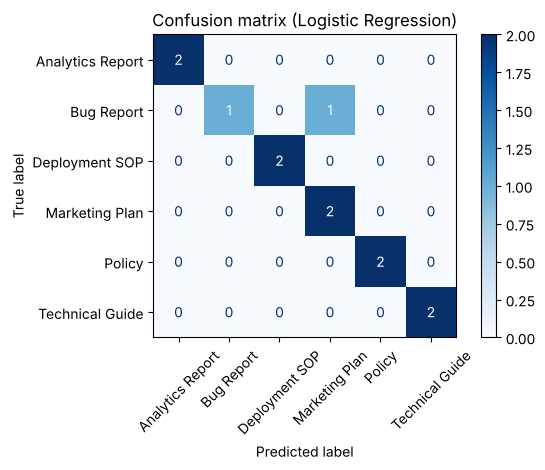

In [7]:
ConfusionMatrixDisplay.from_estimator(best_model, X_test_text, y_test, cmap="Blues", xticks_rotation=45)
plt.title("Confusion matrix (" + best_name + ")")
plt.tight_layout()
plt.show()

In [8]:
# Test predictions: true category vs predicted category
test_results = pd.DataFrame({
    "title": df.loc[X_test_text.index, "title"],
    "true category": y_test,
    "predicted category": best_model.predict(X_test_text),
})
test_results["correct"] = test_results["true category"] == test_results["predicted category"]
test_results

,title,true category,predicted category,correct
10,SOP: phased release,Deployment SOP,Deployment SOP,True
17,Bug: purchase button not working on iPad,Bug Report,Bug Report,True
3,Swift concurrency rules,Technical Guide,Technical Guide,True
27,App Store conversion report,Analytics Report,Analytics Report,True
43,Data breach policy,Policy,Policy,True
33,ASO keyword research,Marketing Plan,Marketing Plan,True
35,RoosterFocus 2.0 launch campaign,Marketing Plan,Marketing Plan,True
15,SOP: hotfix release,Deployment SOP,Deployment SOP,True
22,E2E test plan for onboarding,Bug Report,Marketing Plan,False
1,SwiftUI MVVM guide,Technical Guide,Technical Guide,True


### Classifying new documents

Now we use the model with documents that it has never seen. This is how the system would file new knowledge automatically.

In [9]:
new_documents = [
    "The app freezes when I tap restore purchases on iPhone 13. Steps to reproduce: open settings and tap restore. Severity: high.",
    "Upload version 2.3 with Transporter, select the build in App Store Connect and submit it for review.",
    "October ARR was 51,100 USD and monthly churn went down to 4.8 percent.",
    "Plan daily TikTok videos about new year goals and update the App Store keywords for January.",
    "From now on two-factor authentication is mandatory for all employee accounts in GitHub and App Store Connect.",
    "We will replace the CloudKit mirroring with CKSyncEngine and keep SwiftData as the local database.",
]
expected = ["Bug Report", "Deployment SOP", "Analytics Report", "Marketing Plan", "Policy", "Technical Guide"]

predicted = best_model.predict(new_documents)
probability = best_model.predict_proba(new_documents).max(axis=1)   # how sure the model is

new_results = pd.DataFrame({
    "new document": new_documents,
    "expected": expected,
    "predicted": predicted,
    "probability": probability.round(2),
})
new_results

,new document,expected,predicted,probability
0,The app freezes when I tap restore purchases on iPhone 13. Steps to reproduce: open settings and...,Bug Report,Bug Report,0.77
1,"Upload version 2.3 with Transporter, select the build in App Store Connect and submit it for rev...",Deployment SOP,Deployment SOP,0.66
2,"October ARR was 51,100 USD and monthly churn went down to 4.8 percent.",Analytics Report,Analytics Report,0.65
3,Plan daily TikTok videos about new year goals and update the App Store keywords for January.,Marketing Plan,Marketing Plan,0.47
4,From now on two-factor authentication is mandatory for all employee accounts in GitHub and App S...,Policy,Policy,0.27
5,We will replace the CloudKit mirroring with CKSyncEngine and keep SwiftData as the local database.,Technical Guide,Technical Guide,0.58


## 4. Semantic search

The user writes a question in natural language. We convert the question into a TF-IDF vector and compare it with every document using **cosine similarity**:

$$\text{cosine similarity}(q, d) = \frac{q \cdot d}{\|q\| \, \|d\|}$$

The score goes from 0 (nothing in common) to 1 (very similar). The documents with the highest scores are shown first.

In [10]:
def search(query, top_n=3):
    query_vector = vectorizer.transform([query])            # same vectorizer used for the documents
    scores = cosine_similarity(query_vector, X_all)[0]       # one score per document
    best = scores.argsort()[::-1][:top_n]                     # positions of the highest scores
    return pd.DataFrame({
        "title": df.loc[best, "title"].values,
        "category": df.loc[best, "category"].values,
        "similarity score": scores[best].round(3),
    })

print("Query: the app crashes after the update")
search("the app crashes after the update")

Query: the app crashes after the update


,title,category,similarity score
0,Bug: crash after update,Bug Report,0.552
1,ASO keyword research,Marketing Plan,0.185
2,Weekly crash report,Analytics Report,0.144


In [11]:
print("Query: how do I submit the app to the App Store")
search("how do I submit the app to the App Store")

Query: how do I submit the app to the App Store


,title,category,similarity score
0,SOP: submit a build to App Store Connect,Deployment SOP,0.537
1,SOP: in-app purchase setup,Deployment SOP,0.328
2,App Store screenshots test,Marketing Plan,0.285


In [12]:
print("Query: why do users cancel their subscription")
search("why do users cancel their subscription")

Query: why do users cancel their subscription


,title,category,similarity score
0,Cancellation survey results,Analytics Report,0.467
1,Weekly KPI summary,Analytics Report,0.164
2,Bug: restore purchases fails,Bug Report,0.108


In [13]:
# Try your own question here
my_query = "what should a new developer do the first week"
print("Query:", my_query)
search(my_query)

Query: what should a new developer do the first week


,title,category,similarity score
0,New developer onboarding checklist,Policy,0.513
1,November content calendar,Marketing Plan,0.317
2,Weekly KPI summary,Analytics Report,0.177


## 5. Ontology (concept map)

An ontology shows the main concepts of the organization and how they are related. We define the relationships as **(concept, relationship, concept)** and draw them as a graph. Blue nodes are **document types** and orange nodes are **concepts**.

In [14]:
relationships = [
    # concept -> concept
    ("iOS App", "built with", "SwiftUI"),
    ("iOS App", "stores data in", "SwiftData"),
    ("SwiftData", "syncs with", "CloudKit"),
    ("iOS App", "sells", "Subscription"),
    ("Subscription", "uses", "StoreKit 2"),
    ("Subscription", "generates", "Revenue (ARR)"),
    ("Churn", "reduces", "Revenue (ARR)"),
    ("Build", "uploaded to", "App Store Connect"),
    ("Build", "tested in", "TestFlight"),
    ("UI Tests", "find", "Bug"),
    ("Crash", "is a type of", "Bug"),
    ("Social Media", "brings", "Downloads"),
    ("ASO", "brings", "Downloads"),
    ("Downloads", "convert into", "Subscription"),
    ("Privacy", "protects", "User Data"),
    # document type -> concept
    ("Technical Guide", "describes", "SwiftUI"),
    ("Technical Guide", "describes", "SwiftData"),
    ("Deployment SOP", "explains", "Build"),
    ("Deployment SOP", "explains", "App Store Connect"),
    ("Bug Report", "documents", "Bug"),
    ("Bug Report", "documents", "Crash"),
    ("Analytics Report", "measures", "Revenue (ARR)"),
    ("Analytics Report", "measures", "Churn"),
    ("Analytics Report", "measures", "Crash"),
    ("Marketing Plan", "plans", "Social Media"),
    ("Marketing Plan", "plans", "ASO"),
    ("Policy", "defines", "Privacy"),
]
document_types = ["Technical Guide", "Deployment SOP", "Bug Report", "Analytics Report", "Marketing Plan", "Policy"]

pd.DataFrame(relationships, columns=["from", "relationship", "to"])

,from,relationship,to
0,iOS App,built with,SwiftUI
1,iOS App,stores data in,SwiftData
2,SwiftData,syncs with,CloudKit
3,iOS App,sells,Subscription
4,Subscription,uses,StoreKit 2
5,Subscription,generates,Revenue (ARR)
6,Churn,reduces,Revenue (ARR)
7,Build,uploaded to,App Store Connect
8,Build,tested in,TestFlight
9,UI Tests,find,Bug


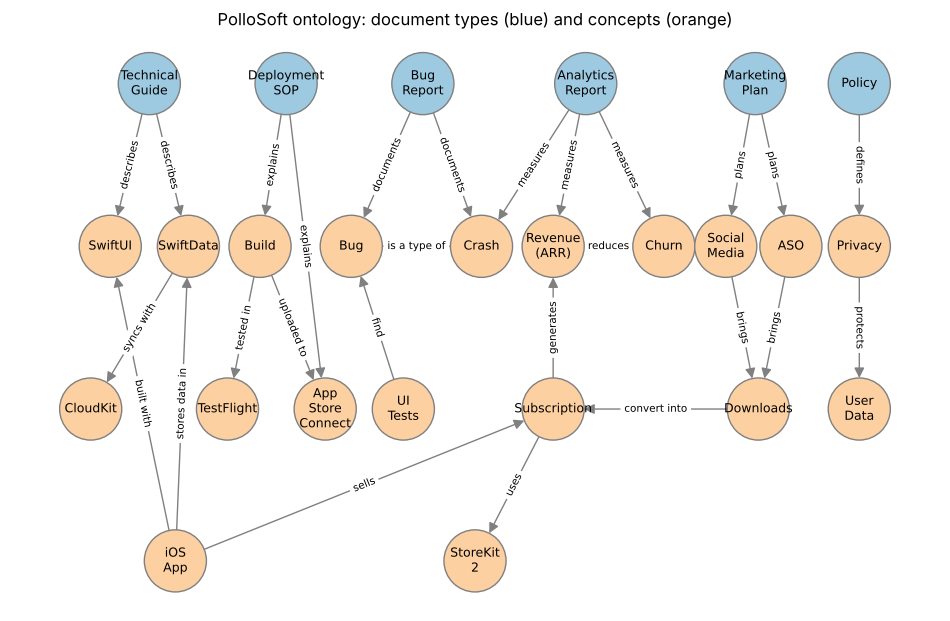

In [15]:
G = nx.DiGraph()
for source, relation, target in relationships:
    G.add_edge(source, target, label=relation)

# We place the nodes by hand so the graph is easy to read:
# document types on top, the concepts they talk about below.
positions = {
    "Technical Guide": (1.2, 8), "Deployment SOP": (5.4, 8), "Bug Report": (9.6, 8),
    "Analytics Report": (14.6, 8), "Marketing Plan": (19.8, 8), "Policy": (23, 8),
    "SwiftUI": (0, 5), "SwiftData": (2.4, 5), "Build": (4.6, 5), "Bug": (7.4, 5), "Crash": (11.4, 5),
    "Revenue (ARR)": (13.6, 5), "Churn": (17.0, 5), "Social Media": (18.9, 5), "ASO": (20.9, 5), "Privacy": (23, 5),
    "CloudKit": (-0.6, 2), "TestFlight": (3.6, 2), "App Store Connect": (6.6, 2), "UI Tests": (9.0, 2),
    "Subscription": (13.6, 2), "Downloads": (19.9, 2), "User Data": (23, 2),
    "iOS App": (2.0, -0.8), "StoreKit 2": (11.2, -0.8),
}
colors = ["#9ecae1" if node in document_types else "#fdd0a2" for node in G.nodes]
labels = {node: node.replace(" ", "\n") for node in G.nodes}   # split long names in two lines

plt.figure(figsize=(12, 7.5))
nx.draw_networkx_nodes(G, positions, node_color=colors, node_size=2000, edgecolors="gray")
nx.draw_networkx_labels(G, positions, labels=labels, font_size=9)
nx.draw_networkx_edges(G, positions, arrows=True, arrowsize=15, edge_color="gray", node_size=2000)
nx.draw_networkx_edge_labels(G, positions, edge_labels=nx.get_edge_attributes(G, "label"), font_size=7.5)
plt.title("PolloSoft ontology: document types (blue) and concepts (orange)")
plt.axis("off")
plt.show()

## Conclusions

- The classifier learned to identify the 6 types of PolloSoft documents using only the words in each document.
- The semantic search finds the right documents for questions written in normal language, which helps employees find knowledge faster.
- The ontology shows how PolloSoft's documents and concepts are connected.

**Limitations:** the dataset is small and was written by us, so the results are only a demonstration. TF-IDF only matches words, so it does not understand synonyms (for example "leave" vs. "churn"). In the future we could use more real documents and sentence embeddings to improve the search.